In [1]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

# Project imports
from fice.datasets import Wikidata

In [2]:
def get_neighbors(data, node):
    incoming_neighbors = data.edge_index[1][data.edge_index[0] == node]
    outgoing_neighbors = data.edge_index[0][data.edge_index[1] == node]
    combinded_neighbors = torch.unique(torch.cat((incoming_neighbors, outgoing_neighbors)))
    return combinded_neighbors

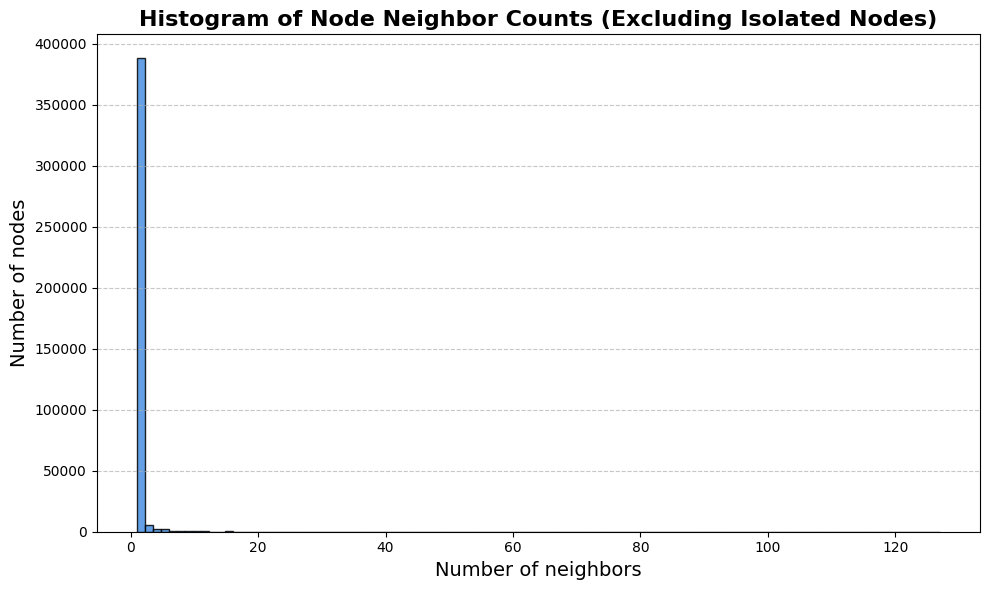

In [3]:
data = Wikidata()

nodes = data.num_nodes
# build undirected adjacency as a sparse tensor and count neighbors per node
ei = data.edge_index
undirected = torch.cat([ei, ei.flip(0)], dim=1)  # ensure both directions
values = torch.ones(undirected.size(1), dtype=torch.int8, device=undirected.device)
adj = torch.sparse_coo_tensor(undirected, values, (nodes, nodes)).coalesce()

counts = torch.sparse.sum(adj, dim=1).to_dense().flatten().cpu().numpy()

# Omit zero neighbor nodes from the histogram
counts_nonzero = counts[counts > 0]

plt.figure(figsize=(10, 6))
plt.hist(counts_nonzero, bins=100, color='#4a90e2', edgecolor='black', alpha=0.85)
plt.xlabel('Number of neighbors', fontsize=14)
plt.ylabel('Number of nodes', fontsize=14)
plt.title('Histogram of Node Neighbor Counts (Excluding Isolated Nodes)', fontsize=16, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()